In [2]:
import matplotlib.pyplot as plt
import numpy as np

import pywt
import ptwt
import pywt.data
import torch

WAVELET_FAMILIES = ["db4", "db6", "db8", "db14", "db16", "db18", "db24", "db26", "db28", "db34", "db36", "db38"]
original = pywt.data.camera()
original = original.astype(np.float64)
original = torch.from_numpy(original)

for x in WAVELET_FAMILIES:

    cA, cD = ptwt.wavedec(
        data=original,
        wavelet=x,
        level=1,
        mode="periodic"
    )

    print(x)
    print(torch.sum(torch.pow(cA, 2)), torch.sum(torch.pow(cD, 2)))



db4
tensor(5.8619e+09, dtype=torch.float64) tensor(12388175.2024, dtype=torch.float64)
db6
tensor(5.9209e+09, dtype=torch.float64) tensor(11094750.2671, dtype=torch.float64)
db8
tensor(5.9801e+09, dtype=torch.float64) tensor(10879995.9945, dtype=torch.float64)
db14
tensor(6.1570e+09, dtype=torch.float64) tensor(10831137.2912, dtype=torch.float64)
db16
tensor(6.2157e+09, dtype=torch.float64) tensor(10952069.7065, dtype=torch.float64)
db18
tensor(6.2737e+09, dtype=torch.float64) tensor(11368082.4936, dtype=torch.float64)
db24
tensor(6.4492e+09, dtype=torch.float64) tensor(11025756.8732, dtype=torch.float64)
db26
tensor(6.5084e+09, dtype=torch.float64) tensor(11346355.4726, dtype=torch.float64)
db28
tensor(6.5674e+09, dtype=torch.float64) tensor(11169488.6948, dtype=torch.float64)
db34
tensor(6.7450e+09, dtype=torch.float64) tensor(11365270.2109, dtype=torch.float64)
db36
tensor(6.8048e+09, dtype=torch.float64) tensor(11189249.1508, dtype=torch.float64)
db38
tensor(6.8652e+09, dtype=torch

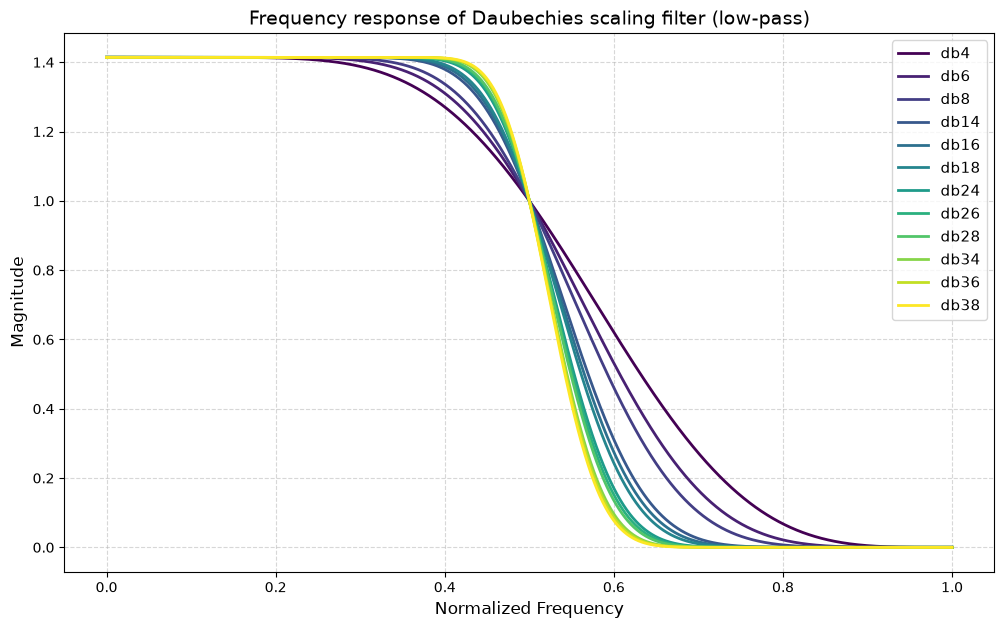

In [10]:
import numpy as np
import matplotlib.pyplot as plt
import pywt
from scipy.signal import freqz

WAVELET_FAMILIES = ["db4", "db6", "db8", "db14", "db16", "db18", "db24", "db26", "db28", "db34", "db36", "db38"]
plt.figure(figsize=(12, 7))

num_colors = len(WAVELET_FAMILIES)
colors = plt.cm.viridis(np.linspace(0, 1, num_colors))

for idx, x in enumerate(WAVELET_FAMILIES):
    db_filter = pywt.Wavelet(x).filter_bank[0]
    w_db, h_db = freqz(db_filter, worN=8000)
    freq_db = w_db / np.pi
    
    plt.plot(freq_db, np.abs(h_db), linewidth=2, label=x, color=colors[idx])

plt.title('Frequency response of Daubechies scaling filter (low-pass)', fontsize=14)
plt.xlabel('Normalized Frequency', fontsize=12)
plt.ylabel('Magnitude', fontsize=12)
plt.grid(True, linestyle='--', alpha=0.5)
plt.legend(fontsize=11, loc='best')
plt.show()
